In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Повторение кода предыдущих недель

Учителя

In [2]:
df_pedagog1 = pd.read_excel('../data/Педагоги.xlsx', sheet_name='2022')
df_pedagog1['year']=2022

df_pedagog2 = pd.read_excel('../data/Педагоги.xlsx', sheet_name='2023')
df_pedagog2['year']=2023

df_pedagog3 = pd.read_excel('../data/Педагоги.xlsx', sheet_name='2024')
df_pedagog3['year']=2024

df_pedagog_all = pd.concat([df_pedagog1, df_pedagog2, df_pedagog3], axis=0)

In [3]:
print(df_pedagog_all.shape[0])

428140


In [4]:
df_pedagog_all = df_pedagog_all.rename(columns={'ID образовательной организации':'school_num',
                                                'Основная должность':'main_position',
                                                'Направление деятельности':'speciality',
                                                'Пол': 'sex',
                                                'Возраст':'age',
                                                'Ученая степень':'academic_degree',
                                                'Квалификационная категория (педагогического работника)':'category_qual',
                                                'Дата присвоения квалификационной категории':'category_date',
                                                'Срок действия квалификационной категории':'category_due',
                                                'Общий стаж работы':'experience_age_all',
                                                'Стаж педагогической работы':'experience_age_pedagogic',
                                                'Предмет':'subject',
                                                'Параллель':'parallel',
                                                'Имеет классное руководство':'class_manager'})

In [5]:
keywords = ['педагог', 'учитель', 'методист', 'преподават', 'воспитатель', 'тьютор']
matching_pedagog = set([item for item in df_pedagog_all.main_position.values
            if any(sub in str(item).lower() for sub in keywords)])
matching_pedagog = set([item for item in matching_pedagog if 'заместитель' not in str(item).lower()])

In [6]:
keywords_manager = ['заместитель', 'ведущий', 'заведующий', 'руководитель', 'начальник', 'главный']
matching_manager = set([item for item in df_pedagog_all.main_position.values
            if any(sub in str(item).lower() for sub in keywords_manager)])

In [7]:
matching_other = set(df_pedagog_all.main_position.unique()).difference(matching_pedagog.union(matching_manager))

In [8]:
matching_dict = {}

for val in matching_pedagog:
    matching_dict[val] = 'учитель'
for val in matching_manager:
    matching_dict[val] = 'руководитель'
for val in matching_other:
    matching_dict[val] = 'другой'

In [9]:
df_pedagog_all['main_position_cat'] = df_pedagog_all['main_position'].map(matching_dict).fillna('не_найдено')

In [10]:
df_pedagog_all['sex'] = df_pedagog_all['sex'].map({'Мужской': 1, 'Женский': 0})

In [11]:
keywords = {'кандидат': 'кандидат', 'доктор': 'доктор'}

def find_academic_degree(text):
    if pd.isna(text):
        return 'не_найдено'

    text = str(text).lower()
    for word, code in keywords.items():
        if word in text:
            return code
    return 'не_найдено'

df_pedagog_all['academic_degree_cat'] = df_pedagog_all['academic_degree'].apply(find_academic_degree)

In [12]:
keywords = {'высшая': 'высшая', 'первая': 'первая', 'вторая': 'вторая'}

def find_category_qual(text):
    if pd.isna(text):
        return 'не_найдено'

    text = str(text).lower()
    for word, code in keywords.items():
        if word in text:
            return code
    return 'не_найдено'

# Применяем функцию
df_pedagog_all['category_qual_cat'] = df_pedagog_all['category_qual'].apply(find_category_qual)

In [13]:
df_pedagog_all['category_date'] = df_pedagog_all['category_date'].astype('Int64')
df_pedagog_all['category_due'] = df_pedagog_all['category_due'].astype('Int64')

In [14]:
df_pedagog_all['category_active'] = df_pedagog_all.apply(lambda row: "не было" if pd.isna(row['category_due']) # Если нет данных
                                    else ("активно" if pd.to_datetime(row['category_due']) > pd.to_datetime(row['year']) # Если текущий год меньше года действия
                                    else "не активно"), axis=1)

In [15]:
df_pedagog_all['experience_age_other'] = df_pedagog_all.experience_age_all - df_pedagog_all.experience_age_pedagogic

In [16]:
df_pedagog_all['n_unique_subjects'] = (
    df_pedagog_all.groupby(['year', 'id'])['subject'].transform('nunique')
)

In [17]:
df_pedagog_all['min_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('min')
)

In [18]:
df_pedagog_all['max_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('max')
)

In [19]:
df_pedagog_all['n_unique_parallel'] = (
    df_pedagog_all.groupby(['year', 'id'])['parallel'].transform('nunique')
)

In [20]:
df_pedagog_all['class_manager'] = df_pedagog_all['class_manager'].map({'Да': 1, 'Нет': 0})

Повторение предобработки 5-ой недели

In [21]:
df_pedagog_all = df_pedagog_all.sort_values(['id', 'year'])
df_pedagog_all['max_year'] = df_pedagog_all.groupby('id')['year'].transform('max')
df_pedagog_all['is_out_next_year'] = (df_pedagog_all['year'] == df_pedagog_all['max_year']).astype(int)
df_pedagog_all = df_pedagog_all.drop(columns=['max_year'])

In [22]:
df_pedagog_all.head(5)

,id,school_num,main_position,speciality,sex,age,academic_degree,category_qual,category_date,category_due,...,main_position_cat,academic_degree_cat,category_qual_cat,category_active,experience_age_other,n_unique_subjects,min_parallel,max_parallel,n_unique_parallel,is_out_next_year
95509,0000c29d68,121,Учитель,английского языка,0,26,NaN,Первая категория,2021,2026,...,учитель,не_найдено,первая,активно,0,1,5,8,2,0
95510,0000c29d68,121,Учитель,английского языка,0,26,NaN,Первая категория,2019,2026,...,учитель,не_найдено,первая,активно,0,1,5,8,2,0
127198,0000c29d68,121,Учитель,английского языка,0,27,NaN,Первая категория,2021,2026,...,учитель,не_найдено,первая,активно,0,1,6,9,2,0
127199,0000c29d68,121,Учитель,английского языка,0,27,NaN,Первая категория,2021,2026,...,учитель,не_найдено,первая,активно,0,1,6,9,2,0
127200,0000c29d68,121,Учитель,английского языка,0,27,NaN,Первая категория,2021,2026,...,учитель,не_найдено,первая,активно,0,1,6,9,2,0


In [23]:
df_pedagog_all.shape

(428140, 26)

#Первичная предобработка

In [24]:
df_pedagog_all['speciality'].unique()

<ArrowStringArray>
[                                               'английского языка',
                                                                nan,
                                                'начальных классов',
                                                         'биологии',
                                                       'математики',
                                                   'русского языка',
                                                           'физики',
                                                          'истории',
                                       'изобразительного искусства',
                                              'физической культуры',
                                                        'географии',
                                                      'информатики',
                                                       'технологии',
                                                            'химии',
               

In [25]:
RULES = {
    'учитель': [
        'английского языка', 'русского языка', 'французского языка',
        'немецкого языка', 'испанского языка', 'итальянского языка',
        'китайского языка', 'арабского языка', 'родного языка',
        'родной литературы', 'литературы', 'литературного чтения',
        'истории', 'всеобщей истории', 'истории России',
        'обществознания', 'обществознания и естествознания (окружающий мир)',
        'права', 'экономики',
        'основ духовно-нравственной культуры народов России',
        'математики', 'алгебры', 'геометрии', 'физики', 'информатики',
        'математики и информатики', 'в сфере ИКТ', 'естествознания',
        'биологии', 'химии', 'географии',
        'изобразительного искусства', 'музыки', 'технологии',
        'физической культуры', 'основ безопасности жизнедеятельности',
        'начальных классов',
    ],

    'воспитатель': [
        'офицер кадетского класса', 'офицер-воспитатель кадетского класса',
        'по социальной работе',
        'по социализации, воспитанию и безопасности обучающихся',
        'по профориентации',
        'группы полного дня, группы ОВЗ', 'группы полного дня',
        'группы продленного дня', 'группы кратковременного пребывания',
        'группы ОВЗ', 'интерната, группы ОВЗ',
    ],

    'управление': [
        'по контролю качества образования', 'учебной части',
        'по содержанию образования, конвергенции образовательных программ',
        'по комплексной безопасности',
        'по материально-техническому обеспечению',
        'по управлению ресурсами', 'по питанию',
        'по финансово-экономической деятельности', 'по учету контингента',
        'по музейной работе', 'учебно-производственной мастерской',
    ],
}

In [26]:
value_to_group = {}
for group, values in RULES.items():
    for v in values:
        value_to_group[v.strip().lower()] = group


def categorize(value):
    if pd.isna(value):
        return 'не указано'
    v = str(value).strip().lower()
    return value_to_group.get(v, 'прочее')

In [27]:
df_pedagog_all['speciality_cat'] = df_pedagog_all['speciality'].apply(categorize)

In [28]:
df_pedagog_all.head(5)

,id,school_num,main_position,speciality,sex,age,academic_degree,category_qual,category_date,category_due,...,academic_degree_cat,category_qual_cat,category_active,experience_age_other,n_unique_subjects,min_parallel,max_parallel,n_unique_parallel,is_out_next_year,speciality_cat
95509,0000c29d68,121,Учитель,английского языка,0,26,NaN,Первая категория,2021,2026,...,не_найдено,первая,активно,0,1,5,8,2,0,учитель
95510,0000c29d68,121,Учитель,английского языка,0,26,NaN,Первая категория,2019,2026,...,не_найдено,первая,активно,0,1,5,8,2,0,учитель
127198,0000c29d68,121,Учитель,английского языка,0,27,NaN,Первая категория,2021,2026,...,не_найдено,первая,активно,0,1,6,9,2,0,учитель
127199,0000c29d68,121,Учитель,английского языка,0,27,NaN,Первая категория,2021,2026,...,не_найдено,первая,активно,0,1,6,9,2,0,учитель
127200,0000c29d68,121,Учитель,английского языка,0,27,NaN,Первая категория,2021,2026,...,не_найдено,первая,активно,0,1,6,9,2,0,учитель


In [29]:
df_pedagog_clean = df_pedagog_all.drop_duplicates(subset=['id', 'year'], keep='first')

In [30]:
del df_pedagog_clean['academic_degree']
del df_pedagog_clean['main_position']
del df_pedagog_clean['speciality']
del df_pedagog_clean['category_qual']
del df_pedagog_clean['subject']
del df_pedagog_clean['parallel']

Убираем столбцы с высокой корреляцией, согласно неделе 5 и 2024 год (так как на основе его мы сделали целевую метку)

In [31]:
del df_pedagog_clean['age']
del df_pedagog_clean['experience_age_all']
del df_pedagog_clean['category_due']

df_pedagog_clean = df_pedagog_clean[df_pedagog_clean['year'] != 2024]

In [32]:
df_pedagog_clean.head()

,id,school_num,sex,category_date,experience_age_pedagogic,class_manager,year,main_position_cat,academic_degree_cat,category_qual_cat,category_active,experience_age_other,n_unique_subjects,min_parallel,max_parallel,n_unique_parallel,is_out_next_year,speciality_cat
95509,0000c29d68,121,0,2021,5,1,2022,учитель,не_найдено,первая,активно,0,1,5,8,2,0,учитель
127198,0000c29d68,121,0,2021,6,1,2023,учитель,не_найдено,первая,активно,0,1,6,9,2,0,учитель
87587,000d0f08a6,229,0,2021,30,0,2022,учитель,не_найдено,высшая,активно,0,2,5,11,5,0,не указано
116624,000d0f08a6,229,0,2021,31,0,2023,учитель,не_найдено,высшая,активно,0,1,2,11,5,0,учитель
45188,000ee8f2b6,442,0,2019,10,1,2022,учитель,не_найдено,первая,активно,17,6,2,4,3,0,не указано


In [33]:
df_pedagog_clean.info()

<class 'pandas.DataFrame'>
Index: 35632 entries, 95509 to 61723
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   id                        35632 non-null  str  
 1   school_num                35632 non-null  int64
 2   sex                       35632 non-null  int64
 3   category_date             28034 non-null  Int64
 4   experience_age_pedagogic  35632 non-null  int64
 5   class_manager             35632 non-null  int64
 6   year                      35632 non-null  int64
 7   main_position_cat         35632 non-null  str  
 8   academic_degree_cat       35632 non-null  str  
 9   category_qual_cat         35632 non-null  str  
 10  category_active           35632 non-null  str  
 11  experience_age_other      35632 non-null  int64
 12  n_unique_subjects         35632 non-null  int64
 13  min_parallel              35632 non-null  int64
 14  max_parallel              35632 non-null  int64
 1

# Обработка категориальных данных

## 1. Инвентаризация категориальных признаков

После этапа первичной очистки в датасете `df_pedagog_clean` остались следующие столбцы, требующие анализа и кодирования:
* **Текстовые/Категориальные:** `main_position_cat`, `academic_degree_cat`, `category_qual_cat`, `category_active`, `speciality_cat`
* **ID-подобные:** `school_num`, `year`
* **Уже бинарные (0/1):** `sex`, `class_manager`, `is_out_next_year`
* **Количественный:** `category_date` (год получения категории)
* **Служебный:** `id`

In [34]:
# Анализ частот категорий для принятия решений по кодированию
print(df_pedagog_clean['main_position_cat'].value_counts(),"\n")
print(df_pedagog_clean['academic_degree_cat'].value_counts(),"\n")
print(df_pedagog_clean['category_qual_cat'].value_counts(),"\n")
print(df_pedagog_clean['category_active'].value_counts(),"\n")
print(df_pedagog_clean['speciality_cat'].value_counts(),"\n")

# Проверка пропусков
print("Пропуски в category_date:")
print(df_pedagog_clean['category_date'].isnull().sum())

main_position_cat
учитель         34908
руководитель      384
другой            340
Name: count, dtype: int64 

academic_degree_cat
не_найдено    34843
кандидат        784
доктор            5
Name: count, dtype: int64 

category_qual_cat
высшая        18130
первая         9690
не_найдено     7736
вторая           76
Name: count, dtype: int64 

category_active
активно       22113
не было        8316
не активно     5203
Name: count, dtype: int64 

speciality_cat
не указано     19089
учитель        16261
воспитатель      158
управление       124
Name: count, dtype: int64 

Пропуски в category_date:
7598


## 2. Анализ пропусков и «специальных» значений

В наших данных пропуски часто являются не ошибкой сбора, а осмысленным состоянием (отсутствием признака).
* `academic_degree_cat`: значение `не_найдено` означает отсутствие ученой степени.
* `category_qual_cat`: значение `не_найдено` означает, что у учителя нет квалификационной категории.
* `category_active`: значение `не было` означает, что категория никогда не присваивалась.
* `speciality_cat`: значение `не указано` означает, что направление деятельности не задано в исходных данных.
* **`category_date`**: содержит 7598 пропусков (`NaN`). Пропуск здесь жёстко коррелирует с отсутствием категории (`не_найдено`). Мы заполним его заглушкой `1970`, однако сырой год не является линейным числовым признаком и может ввести модель в заблуждение (расстояние между 1970 и 2020 годами не имеет физического смысла). Согласно методологии из лонгрида, этот признак лучше **удалить** перед подачей в модель.

## 3. Классификация признаков

| Признак | Тип | Обоснование |
|---|---|---|
| `main_position_cat` | Номинальный | Нет порядка (учитель, руководитель, другой). |
| `academic_degree_cat` | Ординальный | Есть порядок (нет степени < есть степень). |
| `category_qual_cat` | Ординальный | Есть порядок (нет < ниже высшей < высшая). |
| `category_active` | Ординальный | Есть порядок (не было < не активно < активно). |
| `speciality_cat` | Номинальный | Нет порядка (учитель, воспитатель, управление, не указано). |
| `school_num` | ID-подобный (высокая кардинальность) | Идентификатор школы (459 значений), порядка нет. |
| `sex`, `class_manager` | Бинарные | Уже представлены как 0 и 1. |

## 4. Применение кодирования

### One-Hot Encoding

In [35]:
dummies = pd.get_dummies(df_pedagog_clean['main_position_cat'], prefix='main_position', drop_first=False).astype(int)

dummies = dummies.rename(columns={
    'main_position_другой': 'main_position_other',
    'main_position_учитель': 'main_position_teacher',
    'main_position_руководитель': 'main_position_head'
})

df_pedagog_clean = pd.concat([df_pedagog_clean, dummies], axis=1)

In [36]:
dummies = pd.get_dummies(df_pedagog_clean['speciality_cat'], prefix='speciality', drop_first=False).astype(int)

dummies = dummies.rename(columns={
    'speciality_не указано': 'speciality_not_specified',
    'speciality_учитель': 'speciality_teacher',
    'speciality_воспитатель': 'speciality_educator',
    'speciality_управление': 'speciality_management'
})

df_pedagog_clean = pd.concat([df_pedagog_clean, dummies], axis=1)

In [37]:
df_pedagog_clean.head()

,id,school_num,sex,category_date,experience_age_pedagogic,class_manager,year,main_position_cat,academic_degree_cat,category_qual_cat,...,n_unique_parallel,is_out_next_year,speciality_cat,main_position_other,main_position_head,main_position_teacher,speciality_educator,speciality_not_specified,speciality_management,speciality_teacher
95509,0000c29d68,121,0,2021,5,1,2022,учитель,не_найдено,первая,...,2,0,учитель,0,0,1,0,0,0,1
127198,0000c29d68,121,0,2021,6,1,2023,учитель,не_найдено,первая,...,2,0,учитель,0,0,1,0,0,0,1
87587,000d0f08a6,229,0,2021,30,0,2022,учитель,не_найдено,высшая,...,5,0,не указано,0,0,1,0,1,0,0
116624,000d0f08a6,229,0,2021,31,0,2023,учитель,не_найдено,высшая,...,5,0,учитель,0,0,1,0,0,0,1
45188,000ee8f2b6,442,0,2019,10,1,2022,учитель,не_найдено,первая,...,3,0,не указано,0,0,1,0,1,0,0


### Ordinal Encoding

Создаем карту. Для степени создаем "есть" и "нет", так как докторов слишком мало. Аналогично с первой и второй категорией.

In [38]:
academic_degree_map = {
    'не_найдено': 0,
    'кандидат': 1,
    'доктор': 1
}

category_qual_map = {
    'не_найдено': 0,
    'первая': 1,
    'вторая': 1,
    'высшая': 2
}

category_active_map = {
    'не было': 0,
    'не активно': 1,
    'активно': 2
}

In [39]:
df_pedagog_clean['academic_degree_cat'] = df_pedagog_clean['academic_degree_cat'].map(academic_degree_map)
df_pedagog_clean['category_qual_cat'] = df_pedagog_clean['category_qual_cat'].map(category_qual_map)
df_pedagog_clean['category_active'] = df_pedagog_clean['category_active'].map(category_active_map)

print("academic_degree_cat:", df_pedagog_clean['academic_degree_cat'].unique())
print("category_qual_cat:", df_pedagog_clean['category_qual_cat'].unique())
print("category_active:", df_pedagog_clean['category_active'].unique())

print(f"\nПропуски после кодирования:")
print(df_pedagog_clean[['academic_degree_cat', 'category_qual_cat', 'category_active']].isnull().sum())

academic_degree_cat: [0 1]
category_qual_cat: [1 2 0]
category_active: [2 0 1]

Пропуски после кодирования:
academic_degree_cat    0
category_qual_cat      0
category_active        0
dtype: int64


In [40]:
df_pedagog_clean.info()

<class 'pandas.DataFrame'>
Index: 35632 entries, 95509 to 61723
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   id                        35632 non-null  str  
 1   school_num                35632 non-null  int64
 2   sex                       35632 non-null  int64
 3   category_date             28034 non-null  Int64
 4   experience_age_pedagogic  35632 non-null  int64
 5   class_manager             35632 non-null  int64
 6   year                      35632 non-null  int64
 7   main_position_cat         35632 non-null  str  
 8   academic_degree_cat       35632 non-null  int64
 9   category_qual_cat         35632 non-null  int64
 10  category_active           35632 non-null  int64
 11  experience_age_other      35632 non-null  int64
 12  n_unique_subjects         35632 non-null  int64
 13  min_parallel              35632 non-null  int64
 14  max_parallel              35632 non-null  int64
 1

### Target Encoding

`school_num` — это идентификатор школы. Мы будем использовать **Target Encoding** (замена номера школы на среднее значение целевой переменной `is_out_next_year` внутри этой школы), потому что если мы посчитаем среднее значение целевой переменной по всему датасету (включая тестовые данные 2023 года), произойдет утечка данных. Модель «подглядит» в будущее и метрики на тесте будут ложно завышены.

1. Разделим данные по годам: `train` = 2022 год, `test` = 2023 год.
2. Обучим `TargetEncoder` **только на `train`**.
3. Применим трансформацию к `train` и `test`.

In [41]:
from sklearn.preprocessing import TargetEncoder

# 1. Временной сплит (Train = 2022, Test = 2023)
train_mask = df_pedagog_clean['year'] == 2022
test_mask = df_pedagog_clean['year'] == 2023

X_train = df_pedagog_clean[train_mask].copy()
X_test = df_pedagog_clean[test_mask].copy()

y_train = X_train['is_out_next_year']
y_test = X_test['is_out_next_year']

# 2. Target Encoding для school_num (Обучаем ТОЛЬКО на train!)
te = TargetEncoder(target_type='binary', smooth='auto')
te.fit(X_train[['school_num']], y_train)

X_train['school_num_te'] = te.transform(X_train[['school_num']])
X_test['school_num_te'] = te.transform(X_test[['school_num']])

print(f"Размер X_train: {X_train.shape}")
print(f"Размер X_test: {X_test.shape}")

Размер X_train: (17833, 26)
Размер X_test: (17799, 26)


## 5. Обоснование выбора методов кодирования

1. **One-Hot Encoding (OHE)** применяется к `main_position_cat` и `speciality_cat`. Это номинальные признаки с небольшим числом уровней. OHE не создает ложного математического порядка между категориями. *(Используем `drop_first=False` для сохранения полной информации о базовых категориях).*
2. **Ordinal Encoding** применяется к `academic_degree_cat`, `category_qual_cat`, `category_active`. Эти признаки имеют естественный иерархический порядок. 
   * Редкие категории (`доктор` — 5 шт., `вторая` — 76 шт.) объединены с близкими по смыслу (`кандидат` и `первая`), так как на 5 примерах модель не сможет статистически значимо оценить вес категории.
3. **Target Encoding** будет применен к `school_num`. Это номинальный признак с высокой кардинальностью (459 уникальных школ). OHE создал бы 459 разреженных столбцов. Target Encoding заменит номер школы на вероятность увольнения (целевую переменную) в этой школе.
4. **Бинарные признаки** (`sex`, `class_manager`) оставляем без изменений.

## 6. Удаление исходных категориальных столбцов

In [42]:
df_pedagog_clean = df_pedagog_clean.drop(columns=['main_position_cat'])
df_pedagog_clean = df_pedagog_clean.drop(columns=['speciality_cat'])
cols_to_drop = [
    'id',                # Идентификатор, не несет сигнала
    'year',              # Временная метка, использовалась только для сплита
    'is_out_next_year',  # Целевая переменная (уходит в y)
    'category_date',     # Удаляем, так как это нелинейный маркер пропуска
    'school_num'         # Исходный ID школы, мы заменили его на school_num_te
]

X_train = X_train.drop(columns=[c for c in cols_to_drop if c in X_train.columns])
X_test = X_test.drop(columns=[c for c in cols_to_drop if c in X_test.columns])

# Масштабирование количественных переменных

## 1. Анализ и заполнение пропусков в числовых признаках

In [43]:
# Проверка пропусков в числовых столбцах
print("Пропуски в числовых столбцах:")
print(df_pedagog_clean[['experience_age_pedagogic', 'experience_age_other',
                        'n_unique_subjects', 'min_parallel', 'max_parallel',
                        'n_unique_parallel', 'category_date']].isnull().sum())

Пропуски в числовых столбцах:
experience_age_pedagogic       0
experience_age_other           0
n_unique_subjects              0
min_parallel                   0
max_parallel                   0
n_unique_parallel              0
category_date               7598
dtype: int64


**`category_date`**: содержит 7598 пропусков. Как мы установили в части 1, пропуск здесь означает отсутствие квалификационной категории (жёстко коррелирует с `category_qual_cat == 'не_найдено'`). 

Согласно лонгриду, сырой год (1900, 2016, 2023) — это нелинейный признак, который модель может интерпретировать как "1970 меньше, чем 2020", что лишено смысла. Поэтому этот признак **будет удалён** перед подачей в модель, а не заполнен. Заполнение заглушкой 1970 оставляем только для диагностики распределений.

In [44]:
df_pedagog_clean['category_date'] = df_pedagog_clean['category_date'].fillna(1970)

## 2. Диагностика распределений числовых признаков

### Обработка выбросов

In [45]:
df_pedagog_clean.describe()

,school_num,sex,category_date,experience_age_pedagogic,class_manager,year,academic_degree_cat,category_qual_cat,category_active,experience_age_other,...,max_parallel,n_unique_parallel,is_out_next_year,main_position_other,main_position_head,main_position_teacher,speciality_educator,speciality_not_specified,speciality_management,speciality_teacher
count,35632.000000,35632.000000,35632.0,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,...,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.00000,35632.000000
mean,269.850500,0.151240,2008.735434,18.732207,0.639117,2022.499523,0.022143,1.291704,1.387208,3.364420,...,7.584138,3.265043,0.115514,0.009542,0.010777,0.979681,0.004434,0.535726,0.00348,0.456359
std,147.410867,0.358288,20.234638,12.743855,0.480264,0.500007,0.147151,0.800529,0.839088,6.042762,...,3.372681,1.946904,0.319646,0.097217,0.103252,0.141090,0.066443,0.498729,0.05889,0.498099
min,0.000000,0.000000,1970.0,0.000000,0.000000,2022.000000,0.000000,0.000000,0.000000,-33.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,137.000000,0.000000,2016.0,7.000000,0.000000,2022.000000,0.000000,1.000000,1.000000,0.000000,...,4.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000
50%,275.000000,0.000000,2019.0,18.000000,1.000000,2022.000000,0.000000,2.000000,2.000000,0.000000,...,9.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.00000,0.000000
75%,403.000000,0.000000,2020.0,29.000000,1.000000,2023.000000,0.000000,2.000000,2.000000,4.000000,...,11.000000,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.00000,1.000000
max,534.000000,1.000000,2023.0,67.000000,1.000000,2023.000000,1.000000,2.000000,2.000000,51.000000,...,11.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000


In [46]:
from scipy.stats.mstats import winsorize

df_pedagog_clean['experience_age_pedagogic'] = np.array(
    winsorize(df_pedagog_clean['experience_age_pedagogic'].values, limits=[0.01, 0.01])
)

In [47]:
df_pedagog_clean['n_unique_subjects'] = np.log1p(df_pedagog_clean['n_unique_subjects'])

In [48]:
df_pedagog_clean.describe()

,school_num,sex,category_date,experience_age_pedagogic,class_manager,year,academic_degree_cat,category_qual_cat,category_active,experience_age_other,...,max_parallel,n_unique_parallel,is_out_next_year,main_position_other,main_position_head,main_position_teacher,speciality_educator,speciality_not_specified,speciality_management,speciality_teacher
count,35632.000000,35632.000000,35632.0,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,...,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.00000,35632.000000
mean,269.850500,0.151240,2008.735434,18.705546,0.639117,2022.499523,0.022143,1.291704,1.387208,3.364420,...,7.584138,3.265043,0.115514,0.009542,0.010777,0.979681,0.004434,0.535726,0.00348,0.456359
std,147.410867,0.358288,20.234638,12.678697,0.480264,0.500007,0.147151,0.800529,0.839088,6.042762,...,3.372681,1.946904,0.319646,0.097217,0.103252,0.141090,0.066443,0.498729,0.05889,0.498099
min,0.000000,0.000000,1970.0,0.000000,0.000000,2022.000000,0.000000,0.000000,0.000000,-33.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,137.000000,0.000000,2016.0,7.000000,0.000000,2022.000000,0.000000,1.000000,1.000000,0.000000,...,4.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000
50%,275.000000,0.000000,2019.0,18.000000,1.000000,2022.000000,0.000000,2.000000,2.000000,0.000000,...,9.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.00000,0.000000
75%,403.000000,0.000000,2020.0,29.000000,1.000000,2023.000000,0.000000,2.000000,2.000000,4.000000,...,11.000000,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.00000,1.000000
max,534.000000,1.000000,2023.0,47.000000,1.000000,2023.000000,1.000000,2.000000,2.000000,51.000000,...,11.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000


In [49]:
print(f"Отрицательных значений в experience_age_other: {(df_pedagog_clean['experience_age_other'] < 0).sum()}")

Отрицательных значений в experience_age_other: 88


In [50]:
df_pedagog_clean.loc[df_pedagog_clean['experience_age_other'] < 0, 'experience_age_other'] = 0

In [51]:
df_pedagog_clean.describe()

,school_num,sex,category_date,experience_age_pedagogic,class_manager,year,academic_degree_cat,category_qual_cat,category_active,experience_age_other,...,max_parallel,n_unique_parallel,is_out_next_year,main_position_other,main_position_head,main_position_teacher,speciality_educator,speciality_not_specified,speciality_management,speciality_teacher
count,35632.000000,35632.000000,35632.0,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,...,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.00000,35632.000000
mean,269.850500,0.151240,2008.735434,18.705546,0.639117,2022.499523,0.022143,1.291704,1.387208,3.378592,...,7.584138,3.265043,0.115514,0.009542,0.010777,0.979681,0.004434,0.535726,0.00348,0.456359
std,147.410867,0.358288,20.234638,12.678697,0.480264,0.500007,0.147151,0.800529,0.839088,6.019634,...,3.372681,1.946904,0.319646,0.097217,0.103252,0.141090,0.066443,0.498729,0.05889,0.498099
min,0.000000,0.000000,1970.0,0.000000,0.000000,2022.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,137.000000,0.000000,2016.0,7.000000,0.000000,2022.000000,0.000000,1.000000,1.000000,0.000000,...,4.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.00000,0.000000
50%,275.000000,0.000000,2019.0,18.000000,1.000000,2022.000000,0.000000,2.000000,2.000000,0.000000,...,9.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.00000,0.000000
75%,403.000000,0.000000,2020.0,29.000000,1.000000,2023.000000,0.000000,2.000000,2.000000,4.000000,...,11.000000,5.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.00000,1.000000
max,534.000000,1.000000,2023.0,47.000000,1.000000,2023.000000,1.000000,2.000000,2.000000,51.000000,...,11.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000


In [52]:
print(f"\nМинимальное значение experience_age_other после обработки: {df_pedagog_clean['experience_age_other'].min()}")
print(f"Максимальное значение experience_age_pedagogic после винзоризации: {df_pedagog_clean['experience_age_pedagogic'].max()}")


Минимальное значение experience_age_other после обработки: 0
Максимальное значение experience_age_pedagogic после винзоризации: 47


### Расчёт skewness и kurtosis

Для каждого числового признака посчитаем:
- **skewness** (асимметрия): `|skew| < 0.5` — симметричное, `0.5–1` — умеренная, `> 1` — выраженная
- **kurtosis** (эксцесс): высокие значения указывают на тяжёлые хвосты и выбросы

Результаты диагностики определят выбор скейлера для каждого признака.

In [53]:
from scipy.stats import skew, kurtosis

num_cols = ['experience_age_pedagogic', 'experience_age_other',
            'n_unique_subjects', 'min_parallel', 'max_parallel',
            'n_unique_parallel', 'category_date']

print(f"{'Признак':<30} {'Skew':>8} {'Kurtosis':>10}  Интерпретация")
print("-" * 90)

for col in num_cols:
    s = skew(df_pedagog_clean[col])
    k = kurtosis(df_pedagog_clean[col])
    
    # Интерпретация
    if abs(s) < 0.5:
        interp = "симметричное"
    elif abs(s) < 1:
        interp = "умеренная асимметрия"
    else:
        interp = "сильная асимметрия / тяжёлые хвосты"
    
    if k > 3:
        interp += " + выбросы"
    
    print(f"{col:<30} {s:>+8.2f} {k:>+10.2f}  {interp}")

Признак                            Skew   Kurtosis  Интерпретация
------------------------------------------------------------------------------------------
experience_age_pedagogic          +0.21      -1.07  симметричное
experience_age_other              +2.55      +7.63  сильная асимметрия / тяжёлые хвосты + выбросы
n_unique_subjects                 -0.09      -1.14  симметричное
min_parallel                      +0.24      -0.58  симметричное
max_parallel                      -0.58      -1.11  умеренная асимметрия
n_unique_parallel                 +0.62      -0.21  умеренная асимметрия
category_date                     -1.38      -0.07  сильная асимметрия / тяжёлые хвосты


## 3–4. Выбор и обоснование методов масштабирования

На основе диагностики распределений разделим числовые признаки на 4 группы:

| Группа | Признаки | Метод | Обоснование |
|--------|----------|-------|-------------|
| **Target Encoding** | `school_num` | `TargetEncoder` | Высокая кардинальность (459 школ), номинальный тип. OHE создал бы 459 разреженных столбцов. |
| **StandardScaler** | `category_qual_cat`, `n_unique_subjects`, `n_unique_parallel`, `experience_age_pedagogic` | `StandardScaler` | Симметричные или умеренно скошенные распределения, выраженных выбросов нет (после винзоризации/логарифмирования). StandardScaler даёт нулевое среднее и единичную дисперсию — оптимально для линейных моделей. |
| **MinMaxScaler** | `category_active`, `min_parallel`, `max_parallel` | `MinMaxScaler` | Ограниченный известный диапазон: 0–2 для ординального `category_active`, 1–11 для счётчиков параллелей. MinMax сохраняет естественную интерпретацию. |
| **RobustScaler** | `experience_age_other` | `RobustScaler` | Skew +2.55 и Kurtosis +7.63 — тяжёлые хвосты. StandardScaler и MinMaxScaler здесь пострадают от выбросов, Robust использует медиану и IQR, устойчив к экстремумам. |
| **Passthrough** (не масштабируем) | `sex`, `class_manager`, `academic_degree_cat`, все OHE-столбцы | — | Бинарные признаки уже в идеальном диапазоне {0, 1}. Масштабирование превратит их в дробные и затруднит интерпретацию. |
| **Drop** (удаляем) | `id`, `year`, `category_date`, `is_out_next_year` | — | Служебные столбцы. `category_date` удалён как нелинейный маркер пропуска. |

Pipeline гарантирует, что `fit()` каждого скейлера (включая `TargetEncoder`) вызывается **только на train**. Test использует уже зафиксированные параметры — утечка данных невозможна.

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, TargetEncoder
from sklearn.linear_model import LogisticRegression

# 1. Временной сплит (Train = 2022, Test = 2023)
X_train = df_pedagog_clean[df_pedagog_clean['year'] == 2022].drop(
    columns=['id', 'is_out_next_year', 'year', 'category_date'])
y_train = df_pedagog_clean[df_pedagog_clean['year'] == 2022]['is_out_next_year']

X_test = df_pedagog_clean[df_pedagog_clean['year'] == 2023].drop(
    columns=['id', 'is_out_next_year', 'year', 'category_date'])
y_test = df_pedagog_clean[df_pedagog_clean['year'] == 2023]['is_out_next_year']

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

# 2. Распределение признаков по группам скейлеров
te_cols     = ['school_num']
std_cols    = ['category_qual_cat', 'n_unique_subjects',
               'n_unique_parallel', 'experience_age_pedagogic']
minmax_cols = ['category_active', 'min_parallel', 'max_parallel']
robust_cols = ['experience_age_other']
bin_cols    = ['sex', 'class_manager', 'academic_degree_cat',
               'main_position_other', 'main_position_head', 'main_position_teacher', 'speciality_educator', 
               'speciality_not_specified', 'speciality_management', 'speciality_teacher']

# 3. ColumnTransformer: разные скейлеры для разных групп
preprocessor = ColumnTransformer([
    ('te',     TargetEncoder(target_type='binary', smooth='auto'), te_cols),
    ('std',    StandardScaler(),  std_cols),
    ('minmax', MinMaxScaler(),    minmax_cols),
    ('robust', RobustScaler(),    robust_cols),
    ('bin',    'passthrough',     bin_cols),
])

# 4. Pipeline: препроцессор + модель
pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42,
    )),
])

# 5. Обучение и предсказание
pipe.fit(X_train, y_train)

y_pred  = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

X_train shape: (17833, 19)
X_test shape: (17799, 19)


In [55]:
# Проверим, что масштабирование применилось корректно
X_train_scaled = pipe.named_steps['prep'].transform(X_train)
X_test_scaled  = pipe.named_steps['prep'].transform(X_test)

# Имена признаков после трансформации
feature_names = (
    ['school_num_te'] +
    std_cols +
    minmax_cols +
    robust_cols +
    bin_cols
)

df_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
df_test_scaled  = pd.DataFrame(X_test_scaled, columns=feature_names)

print("=== Статистика train после масштабирования ===")
print(df_train_scaled.describe().round(3).T[['mean', 'std', 'min', 'max']])

print("\n=== Проверка отсутствия утечки: статистики test не использовались при fit ===")
print(f"Среднее school_num_te в train: {df_train_scaled['school_num_te'].mean():.4f}")
print(f"Среднее school_num_te в test:  {df_test_scaled['school_num_te'].mean():.4f}")
print("\nРазличие средних — ожидаемо, так как TargetEncoder обучался только на train.")

=== Статистика train после масштабирования ===
                           mean    std    min     max
school_num_te             0.111  0.049  0.000   0.407
category_qual_cat         0.000  1.000 -1.657   0.872
n_unique_subjects         0.000  1.000 -1.381   3.020
n_unique_parallel         0.000  1.000 -1.166   4.013
experience_age_pedagogic -0.000  1.000 -1.479   2.240
category_active           0.716  0.416  0.000   1.000
min_parallel              0.351  0.238  0.000   1.000
max_parallel              0.656  0.336  0.000   1.000
experience_age_other      0.858  1.526  0.000  12.750
sex                       0.151  0.358  0.000   1.000
class_manager             0.637  0.481  0.000   1.000
academic_degree_cat       0.022  0.148  0.000   1.000
main_position_other       0.009  0.093  0.000   1.000
main_position_head        0.011  0.106  0.000   1.000
main_position_teacher     0.980  0.140  0.000   1.000
speciality_educator       0.000  0.013  0.000   1.000
speciality_not_specified  0.971  0.

# Анализ корреляции и отбор признаков

In [56]:
# 1. Исключаем school_num_te (Target Encoding) из анализа
cols_for_corr = [c for c in df_train_scaled.columns if c != 'school_num_te']
corr_matrix = df_train_scaled[cols_for_corr].corr()

# 2. Поиск всех пар с |corr| > 0.85
high_corr_pairs = []
cols = corr_matrix.columns
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.85:
            high_corr_pairs.append((cols[i], cols[j], val))

print(f"Найдено пар с |corr| > 0.85: {len(high_corr_pairs)}\n")
print(f"{'Признак 1':<30} | {'Признак 2':<30} | Корреляция")
print("-" * 75)
for col1, col2, val in high_corr_pairs:
    print(f"{col1:<30} | {col2:<30} | {val:+.3f}")

Найдено пар с |corr| > 0.85: 1

Признак 1                      | Признак 2                      | Корреляция
---------------------------------------------------------------------------
speciality_not_specified       | speciality_teacher             | -0.991


**Причина:** В наших данных категории `воспитатель` и `управление` встречаются крайне редко (менее 1% суммарно). Это означает, что в 99.2% случаев учитель принадлежит либо к категории `не указано`, либо к категории `учитель`. Из-за этого столбцы `speciality_not_specified` и `speciality_teacher` почти идеально дополняют друг друга до единицы (если один равен 1, второй почти гарантированно равен 0). Это создаёт строгую отрицательную линейную зависимость (*dummy variable trap*), которая делает матрицу признаков вырожденной и ломает интерпретируемость коэффициентов линейной модели.

**Решение:** Удаляем `speciality_not_specified`, превращая её в **базовую (reference) категорию**. Теперь отсутствие единичных значений во всех оставшихся столбцах группы `speciality_*` будет однозначно трактоваться моделью как «направление деятельности не указано».

In [57]:
cols_to_drop = ['speciality_not_specified']

# Удаляем из отмасштабированных таблиц (для корреляционного анализа)
df_train_scaled = df_train_scaled.drop(columns=cols_to_drop)
df_test_scaled  = df_test_scaled.drop(columns=cols_to_drop)

# ПРОВЕРКА: после очистки пар с |corr| > 0.85 остаться не должно
corr_after = df_train_scaled.drop(columns=['school_num_te']).corr()

pairs_after = []
cols = corr_after.columns
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        val = corr_after.iloc[i, j]
        if abs(val) > 0.85:
            pairs_after.append((cols[i], cols[j], val))

off_diag = corr_after.values[np.triu_indices_from(corr_after, k=1)]
print(f"Пар с |corr| > 0.85 после очистки: {len(pairs_after)}")
print(f"Макс. |corr| вне диагонали после очистки: {np.abs(off_diag).max():.3f}")

Пар с |corr| > 0.85 после очистки: 0
Макс. |corr| вне диагонали после очистки: 0.748


In [58]:
# Финальный пайплайн: модель обучаем на том же наборе признаков, что и в итоговой матрице
bin_cols_final = [c for c in bin_cols if c not in cols_to_drop]

preprocessor_final = ColumnTransformer([
    ('te',     TargetEncoder(target_type='binary', smooth='auto'), te_cols),
    ('std',    StandardScaler(),  std_cols),
    ('minmax', MinMaxScaler(),    minmax_cols),
    ('robust', RobustScaler(),    robust_cols),
    ('bin',    'passthrough',     bin_cols_final),
])

pipe_final = Pipeline([
    ('prep', preprocessor_final),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
])

pipe_final.fit(X_train, y_train)
y_proba_final = pipe_final.predict_proba(X_test)[:, 1]

from sklearn.metrics import roc_auc_score
print(f"ROC-AUC до очистки:   {roc_auc_score(y_test, y_proba):.4f}")
print(f"ROC-AUC после очистки: {roc_auc_score(y_test, y_proba_final):.4f}")

ROC-AUC до очистки:   0.6840
ROC-AUC после очистки: 0.6826
ROC-AUC после очистки: 0.6826


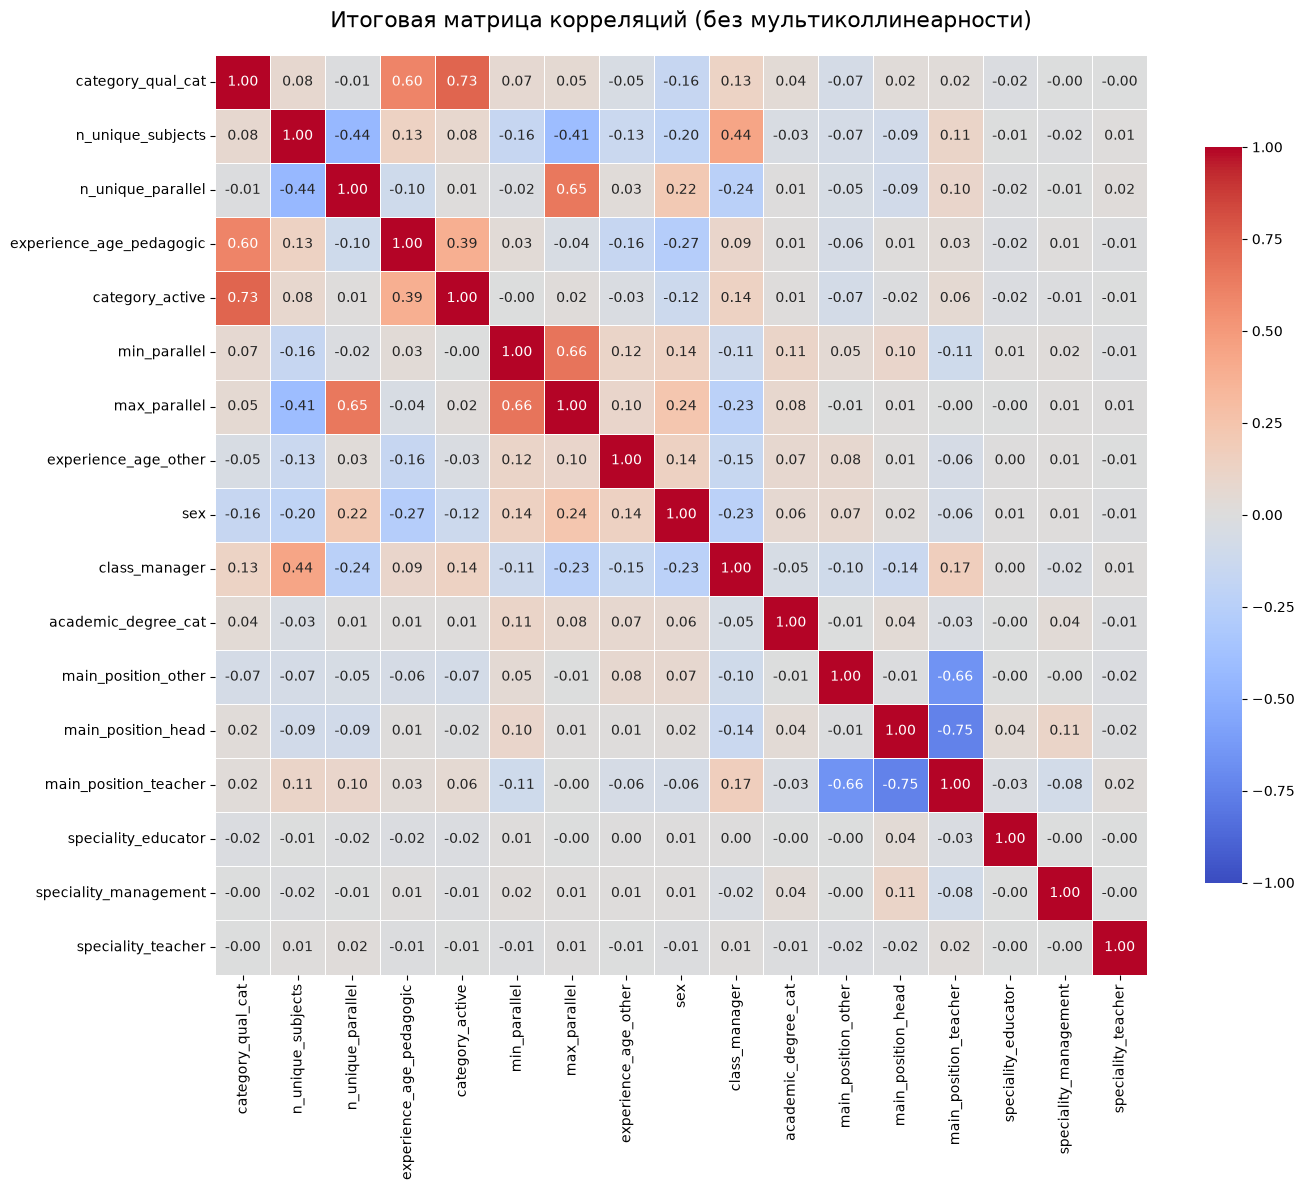

Итоговое количество признаков для модели: 17
Удалено признаков из-за мультиколлинеарности: 1


In [59]:
# Target Encoding (school_num_te) тоже не включаем в итоговую тепловую карту, 
# так как он сконструирован на основе целевой переменной
df_train_scaled = df_train_scaled.drop(columns=['school_num_te']) 

# Визуализация итоговой матрицы
plt.figure(figsize=(14, 12))
sns.heatmap(
    df_train_scaled.corr(), 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=.5, 
    cbar_kws={"shrink": .8},
    vmin=-1, vmax=1
)
plt.title('Итоговая матрица корреляций (без мультиколлинеарности)', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

print(f"Итоговое количество признаков для модели: {df_train_scaled.shape[1]}")
print(f"Удалено признаков из-за мультиколлинеарности: {len(cols_to_drop)}")